# Tutorial 07: Experimental samples

**About this tutorial**
- **Time:** ~20 minutes
- **Status:** experimental
- **Key idea:** set how to read and draw a file, embed, then compute properties

2D images stay on `process_images`. This notebook downloads small public files into `experimental_samples_demo/` and runs `find_files` → `set_data_io` → `process_data` → `compute_properties` → `plot_pca` → `plot_data_by_index` on each set. Those files are not part of the repository.

- **3D image:** sixteen crops of the nuclei channel from the scikit-image `cells3d` volume, fluorescence microscopy from the Allen Institute for Cell Science. `show_fn` returns the grayscale projections.
- **MNIST:** the first training digits, saved as `.npy`. MNIST comes from NIST Special Database 19 and is freely downloadable.
- **YESNO:** a handful of clips from the OpenSLR yes/no set, free for any use.
- **Text:** the lines of Shakespeare's Sonnet 18, which is in the public domain.

Embeddings are still shape `(N, D)`. Each section passes its own small model: a 3D grid for volumes, a 2D grid for digits, frequency bands for audio, and character counts for text. Properties are still one dict of numbers per row. The picture is whatever `show_fn` returns, with shape `(H, W)` or `(H, W, C)`.

In [ ]:
import shutil
import tarfile
import urllib.request
import wave
from pathlib import Path

import numpy as np
import torch
from torchvision.datasets import MNIST

from phenome import PhenoMe
from phenome.experimental import orthogonal_projections, spectrogram_image, text_card
from phenome.utils.model_wrapper import ModelWrapper

ROOT = Path("experimental_samples_demo")
ROOT.mkdir(exist_ok=True)

## 1. 3D fluorescence volume

The nuclei channel of the scikit-image `cells3d` volume, fluorescence microscopy from the Allen Institute for Cell Science. The notebook downloads that TIFF and saves sixteen `(Z, Y, X)` crops as `.npy`. The model average-pools each `(Z, Y, X)` crop onto a coarse grid. `show_fn` returns the three projections as one grayscale image.

Found 16 files total.
DataFrame: 16 files, 4 columns.
Experimental data run: embeddings use the loader from set_data_io(). The image pipeline is not used.


Processing samples:   0%|          | 0/4 [00:00<?, ?it/s]

Computing PCA (16 samples, 32 features → 2 components)...


embeddings (16, 32)
properties {'mean': 6310.90625, 'std': 3012.9853515625}


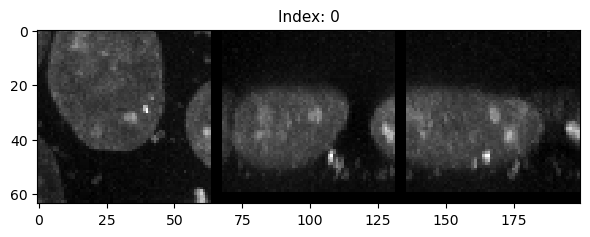


IMAGE DETAILS - Index 0
  Name:     crop_00.npy
  Path:     experimental_samples_demo/volumes/crop_00.npy
  Metadata:
    Filename: crop_00
    Id: crop_00
    Mask_path: nan
--------------------------------------------------
  Properties:
    Mean                          : 6310.91
    Std                           : 3012.99


In [2]:
import tifffile

volume_path = ROOT / "cells3d.tif"
if not volume_path.exists():
    urllib.request.urlretrieve(
        "https://gitlab.com/scikit-image/data/-/raw/2cdc5ce89b334d28f06a58c9f0ca21aa6992a5ba/cells3d.tif",
        volume_path,
    )
stack = tifffile.imread(volume_path)
nuclei = stack[:, 1].astype(np.float32)
vol_dir = ROOT / "volumes"
vol_dir.mkdir(exist_ok=True)
tile = 64
crop_index = 0
for y in range(0, nuclei.shape[1], tile):
    for x in range(0, nuclei.shape[2], tile):
        crop = nuclei[:, y : y + tile, x : x + tile]
        np.save(vol_dir / f"crop_{crop_index:02d}.npy", crop)
        crop_index += 1


def load_volume(path: str) -> np.ndarray:
    return np.load(path)


def show_volume(volume: np.ndarray) -> np.ndarray:
    return orthogonal_projections(volume, axis_order="zyx")


def volume_props(volume: np.ndarray, mask: object) -> dict[str, float]:
    return {"mean": float(np.mean(volume)), "std": float(np.std(volume))}


class VolumeGrid(ModelWrapper):
    """Average of a coarse (Z, Y, X) grid. The batch is (B, Z, Y, X)."""

    def __init__(self) -> None:
        super().__init__(model=object())

    def _get_embeddings(self, tensor: torch.Tensor) -> torch.Tensor:
        pooled = torch.nn.functional.adaptive_avg_pool3d(tensor.unsqueeze(1), (2, 4, 4))
        return pooled.flatten(1)


volumes = PhenoMe(device="cpu", seed=0)
volumes.find_files(str(vol_dir), extensions=[".npy"])
volumes.set_data_io(load_volume, show_volume)
volumes.process_data(VolumeGrid(), batch_size=4)
volumes.compute_properties(additional_property_functions={"any": volume_props})
print("embeddings", volumes.get_embeddings().shape)
print("properties", volumes.results.properties[0])
volumes.plot_pca()
volumes.plot_data_by_index(0)


## 2. MNIST digits

Each file is one 28×28 digit. `show_fn` returns that grayscale array. The model average-pools it on a 4×4 grid.

Found 24 files total.
DataFrame: 24 files, 4 columns.
Experimental data run: embeddings use the loader from set_data_io(). The image pipeline is not used.


Processing samples:   0%|          | 0/3 [00:00<?, ?it/s]

Computing PCA (24 samples, 16 features → 2 components)...


embeddings (24, 16)
properties {'mean': 35.10841751098633, 'std': 79.6488265991211}


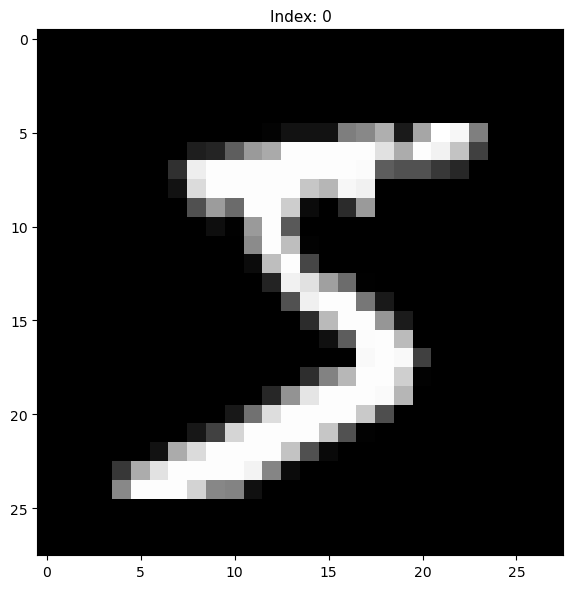


IMAGE DETAILS - Index 0
  Name:     00_5.npy
  Path:     experimental_samples_demo/digits/00_5.npy
  Metadata:
    Filename: 00_5
    Id: 00_5
    Mask_path: nan
--------------------------------------------------
  Properties:
    Mean                          : 35.11
    Std                           : 79.65


In [3]:
digit_dir = ROOT / "digits"
digit_dir.mkdir(exist_ok=True)
mnist = MNIST(str(ROOT / "mnist_raw"), train=True, download=True)
for index in range(24):
    image, label = mnist[index]
    array = np.asarray(image, dtype=np.float32)
    np.save(digit_dir / f"{index:02d}_{label}.npy", array)


def load_digit(path: str) -> np.ndarray:
    return np.load(path)


def show_digit(image: np.ndarray) -> np.ndarray:
    return image


def digit_props(image: np.ndarray, mask: object) -> dict[str, float]:
    return {"mean": float(np.mean(image)), "std": float(np.std(image))}


class DigitGrid(ModelWrapper):
    """Average of a 4×4 grid. The batch is (B, H, W)."""

    def __init__(self) -> None:
        super().__init__(model=object())

    def _get_embeddings(self, tensor: torch.Tensor) -> torch.Tensor:
        pooled = torch.nn.functional.adaptive_avg_pool2d(tensor.unsqueeze(1), (4, 4))
        return pooled.flatten(1)


digits = PhenoMe(device="cpu", seed=0)
digits.find_files(str(digit_dir), extensions=[".npy"])
digits.set_data_io(load_digit, show_digit)
digits.process_data(DigitGrid(), batch_size=8)
digits.compute_properties(additional_property_functions={"any": digit_props})
print("embeddings", digits.get_embeddings().shape)
print("properties", digits.results.properties[0])
digits.plot_pca()
digits.plot_data_by_index(0)

## 3. YESNO clips

A few `.wav` files from OpenSLR, read with the standard-library `wave` module. Lengths differ, so `collate_fn` pads each batch. `show_fn` returns the spectrogram as a grayscale image. The model keeps the log energy of 16 frequency bands.

Found 16 files total.
DataFrame: 16 files, 4 columns.
Experimental data run: embeddings use the loader from set_data_io(). The image pipeline is not used.


Processing samples:   0%|          | 0/4 [00:00<?, ?it/s]

Computing PCA (16 samples, 16 features → 2 components)...


embeddings (16, 16)
properties {'rms': 0.04722515121102333}


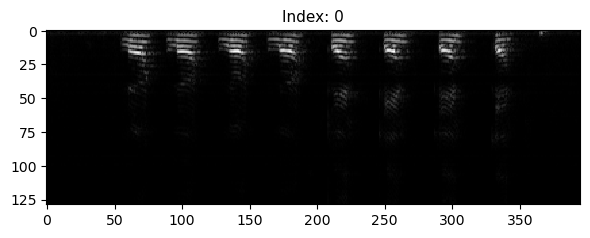


IMAGE DETAILS - Index 0
  Name:     0_0_0_0_1_1_1_1.wav
  Path:     experimental_samples_demo/clips/0_0_0_0_1_1_1_1.wav
  Metadata:
    Filename: 0_0_0_0_1_1_1_1.wav
    Id: 0_0_0_0_1_1_1_1.wav
    Mask_path: nan
--------------------------------------------------
  Properties:
    Rms                           : 0.0472


In [4]:
archive = ROOT / "waves_yesno.tar.gz"
extracted = ROOT / "yesno_archive"
if not any(extracted.glob("**/*.wav")):
    urllib.request.urlretrieve(
        "https://www.openslr.org/resources/1/waves_yesno.tar.gz",
        archive,
    )
    extracted.mkdir(exist_ok=True)
    with tarfile.open(archive) as bundle:
        bundle.extractall(extracted)

clip_dir = ROOT / "clips"
clip_dir.mkdir(exist_ok=True)
for wav_path in sorted(extracted.glob("**/*.wav"))[:16]:
    shutil.copy(wav_path, clip_dir / wav_path.name)


def load_wave(path: str) -> np.ndarray:
    with wave.open(path, "rb") as handle:
        frames = handle.readframes(handle.getnframes())
        width = handle.getsampwidth()
    if width != 2:
        raise ValueError(f"Expected 16-bit wav audio, got sample width {width}.")
    audio = np.frombuffer(frames, dtype="<i2").astype(np.float32)
    return np.ascontiguousarray(audio / 32768.0)


def collate_waves(samples: list[np.ndarray]) -> torch.Tensor:
    width = max(len(sample) for sample in samples)
    rows = np.zeros((len(samples), width), dtype=np.float32)
    for index, sample in enumerate(samples):
        rows[index, : len(sample)] = sample
    return torch.from_numpy(rows)


def show_wave(waveform: np.ndarray) -> np.ndarray:
    return spectrogram_image(waveform, sample_rate=8000, n_fft=256, hop=128)


def wave_props(waveform: np.ndarray, mask: object) -> dict[str, float]:
    return {"rms": float(np.sqrt(np.mean(np.square(waveform))))}


class BandEnergy(ModelWrapper):
    """Log energy in 16 frequency bands. The batch is (B, samples)."""

    def __init__(self) -> None:
        super().__init__(model=object())

    def _get_embeddings(self, tensor: torch.Tensor) -> torch.Tensor:
        spectrum = torch.log1p(torch.fft.rfft(tensor, dim=-1).abs())
        bands = torch.nn.functional.adaptive_avg_pool1d(spectrum.unsqueeze(1), 16)
        return bands.flatten(1)


clips = PhenoMe(device="cpu", seed=0)
clips.find_files(str(clip_dir), extensions=[".wav"])
clips.set_data_io(load_wave, show_wave)
clips.process_data(BandEnergy(), collate_fn=collate_waves, batch_size=4)
clips.compute_properties(additional_property_functions={"any": wave_props})
print("embeddings", clips.get_embeddings().shape)
print("properties", clips.results.properties[0])
clips.plot_pca()
clips.plot_data_by_index(0)


## 4. Public-domain text

Each file is one line of Sonnet 18. The loader returns a string, so `collate_fn` builds a fixed-length tensor. `text_card` draws the line in black on white. The model counts 16 groups of character codes.

Found 14 files total.
DataFrame: 14 files, 4 columns.
Experimental data run: embeddings use the loader from set_data_io(). The image pipeline is not used.


Processing samples:   0%|          | 0/4 [00:00<?, ?it/s]

Computing PCA (14 samples, 16 features → 2 components)...


embeddings (14, 16)
properties {'n_chars': 39}


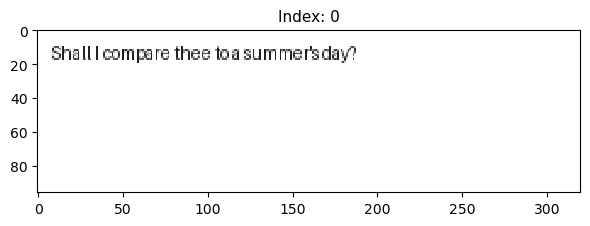


IMAGE DETAILS - Index 0
  Name:     line_00.txt
  Path:     experimental_samples_demo/notes/line_00.txt
  Metadata:
    Filename: line_00.txt
    Id: line_00.txt
    Mask_path: nan
--------------------------------------------------
  Properties:
    N_chars                       : 39


In [5]:
SONNET_18 = [
    "Shall I compare thee to a summer's day?",
    "Thou art more lovely and more temperate:",
    "Rough winds do shake the darling buds of May,",
    "And summer's lease hath all too short a date:",
    "Sometime too hot the eye of heaven shines,",
    "And often is his gold complexion dimm'd;",
    "And every fair from fair sometime declines,",
    "By chance or nature's changing course untrimm'd;",
    "But thy eternal summer shall not fade",
    "Nor lose possession of that fair thou owest;",
    "Nor shall Death brag thou wander'st in his shade,",
    "When in eternal lines to time thou growest:",
    "So long as men can breathe or eyes can see,",
    "So long lives this, and this gives life to thee.",
]

note_dir = ROOT / "notes"
note_dir.mkdir(exist_ok=True)
for index, line in enumerate(SONNET_18):
    (note_dir / f"line_{index:02d}.txt").write_text(line, encoding="utf-8")


def load_text(path: str) -> str:
    return Path(path).read_text(encoding="utf-8")


def collate_text(samples: list[str]) -> torch.Tensor:
    rows = []
    for text in samples:
        ids = [ord(ch) % 64 for ch in text[:32]]
        ids += [0] * (32 - len(ids))
        rows.append(ids)
    return torch.tensor(rows, dtype=torch.float32)


def show_text(text: str) -> np.ndarray:
    return text_card(text)


def text_props(text: str, mask: object) -> dict[str, int]:
    return {"n_chars": len(text)}


class CharGroups(ModelWrapper):
    """Counts of 16 character-code groups. The batch is (B, length), codes in 0..63."""

    def __init__(self) -> None:
        super().__init__(model=object())

    def _get_embeddings(self, tensor: torch.Tensor) -> torch.Tensor:
        codes = tensor.round().to(dtype=torch.long).clamp(0, 63)
        counts = torch.nn.functional.one_hot(codes, 64).float().sum(dim=1)
        return counts.reshape(counts.shape[0], 16, 4).sum(dim=-1)


notes = PhenoMe(device="cpu", seed=0)
notes.find_files(str(note_dir), extensions=[".txt"])
notes.set_data_io(load_text, show_text)
notes.process_data(CharGroups(), collate_fn=collate_text, batch_size=4)
notes.compute_properties(additional_property_functions={"any": text_props})
print("embeddings", notes.get_embeddings().shape)
print("properties", notes.results.properties[0])
notes.plot_pca()
notes.plot_data_by_index(0)
